# Bài thực hành 1 – Phần V.2: Bank Marketing
Khảo sát và tiền xử lý dữ liệu `bank-full.csv` theo các bước của phần hướng dẫn (Titanic).

Thuộc tính quyết định: **y** (khách hàng có đăng ký gửi tiền có kỳ hạn hay không).

## 1. Import thư viện, đọc dữ liệu và thống kê cơ bản

In [12]:
# linear algebra
import numpy as np

# data processing
import pandas as pd

# data visualization
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt

In [13]:
# File bank-full.csv dùng dấu ';' để phân cách cột
df = pd.read_csv('bank-full.csv', sep=';')
df.head(12)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


Trang Kim Đạt 6451071018

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


Trang Kim Đạt 6451071018

In [4]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


Trang Kim Đạt 6451071018

In [5]:
# Thống kê các thuộc tính định tính
df.describe(exclude='number')

,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


Trang Kim Đạt 6451071018

## 2. 5 thuộc tính có nhiều giá trị rỗng nhất
Bộ dữ liệu không có ô trống (NaN) mà ghi giá trị thiếu bằng chữ `'unknown'`, nên ta đổi `'unknown'` thành NaN trước khi đếm.

In [6]:
df = df.replace('unknown', np.nan)

total = df.isnull().sum().sort_values(ascending=False)
percent_1 = df.isnull().sum()/df.isnull().count()*100
percent_2 = (round(percent_1, 1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent_2], axis=1, keys=['Total', '%'])
missing_data.head(5)

,Total,%
poutcome,36959,81.7
contact,13020,28.8
education,1857,4.1
job,288,0.6
age,0,0.0


Trang Kim Đạt 6451071018

Thuộc tính `poutcome` thiếu dữ liệu rất nghiêm trọng (81.7%), `contact` thiếu 28.8%; `education` và `job` chỉ thiếu ít (4.1% và 0.6%).

Đổi thuộc tính quyết định `y` về dạng 0/1 để dễ vẽ biểu đồ và tính tỷ lệ.

In [7]:
df['y'] = df['y'].map({'no': 0, 'yes': 1})
df['y'].value_counts()

y
0    39922
1     5289
Name: count, dtype: int64

Trang Kim Đạt 6451071018

Dữ liệu mất cân bằng: chỉ khoảng 11.7% khách hàng (5,289 / 45,211) đăng ký gửi tiền có kỳ hạn.

## 3. Khảo sát Độ tuổi (age), Tình trạng hôn nhân (marital) và khả năng đăng ký (y)

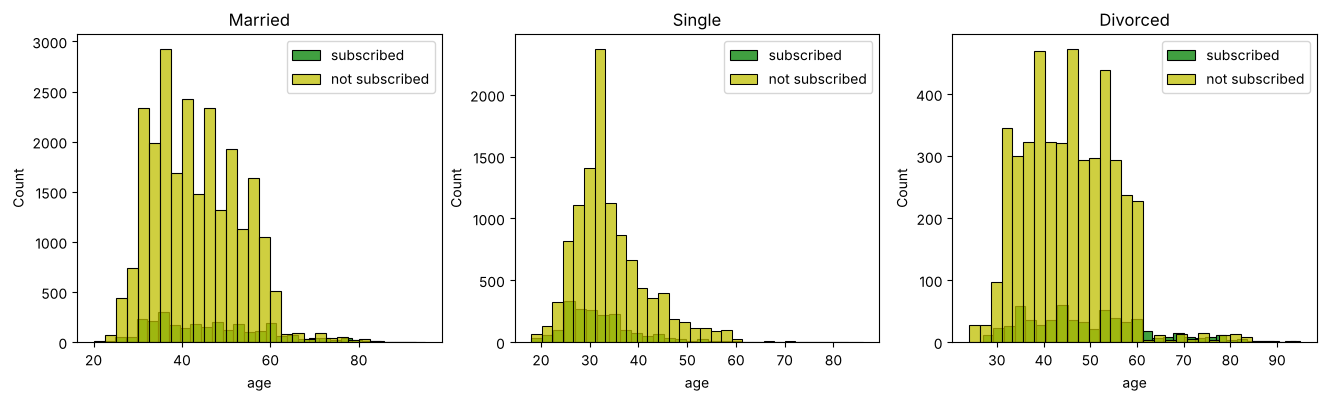

In [8]:
subscribed = 'subscribed'
not_subscribed = 'not subscribed'
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
for ax_i, status in zip(axes, ['married', 'single', 'divorced']):
    group = df[df['marital'] == status]
    ax = sns.histplot(group[group['y']==1].age.dropna(), bins=30, label=subscribed, ax=ax_i, kde=False, color='g')
    ax = sns.histplot(group[group['y']==0].age.dropna(), bins=30, label=not_subscribed, ax=ax_i, kde=False, color='y')
    ax.legend()
    ax.set_title(status.capitalize())

Trang Kim Đạt 6451071018

In [9]:
# Tỷ lệ đăng ký theo nhóm tuổi
df.groupby(pd.cut(df['age'], [0, 25, 30, 40, 50, 60, 100]), observed=True)['y'].mean()

age
(0, 25]      0.239521
(25, 30]     0.144889
(30, 40]     0.102448
(40, 50]     0.090666
(50, 60]     0.100533
(60, 100]    0.422559
Name: y, dtype: float64

Trang Kim Đạt 6451071018

Nhận xét:
- Khách hàng trên 60 tuổi có tỷ lệ đăng ký cao nhất (khoảng 42%), tiếp theo là nhóm từ 25 tuổi trở xuống (khoảng 24%).
- Nhóm 30–60 tuổi chiếm đa số nhưng tỷ lệ đăng ký thấp, chỉ khoảng 9–10%.
- Người độc thân (single) đăng ký nhiều hơn (khoảng 15%) so với người đã kết hôn (khoảng 10%) và ly hôn (khoảng 12%).

## 4. Khảo sát Hình thức liên lạc (contact), Học vấn (education) với y, phân biệt theo Vay mua nhà (housing)

Trang Kim Đạt 6451071018

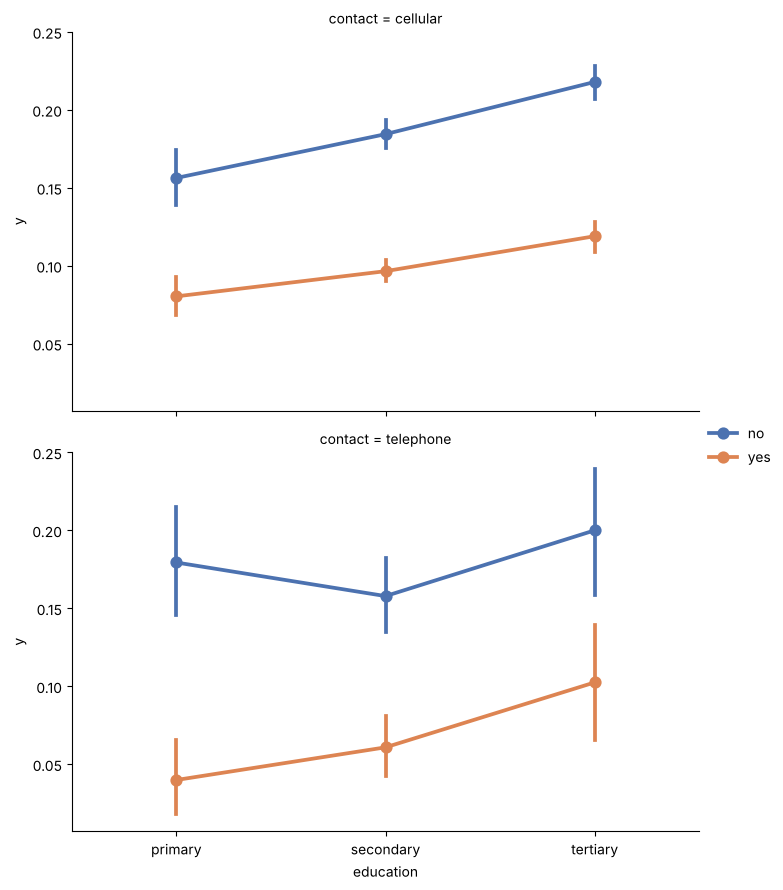

In [10]:
grid = sns.FacetGrid(df.dropna(subset=['contact']), row='contact', height=4.5, aspect=1.6)
grid.map_dataframe(sns.pointplot, x='education', y='y', hue='housing',
                   order=['primary', 'secondary', 'tertiary'], hue_order=['no', 'yes'],
                   palette='deep')
grid.add_legend()

Trang Kim Đạt 6451071018

<Axes: xlabel='education', ylabel='y'>

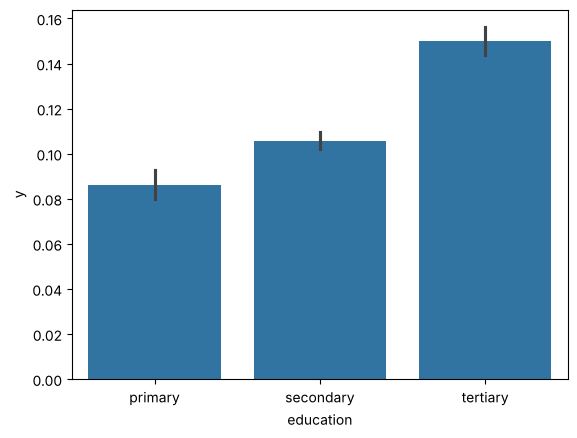

In [11]:
sns.barplot(x='education', y='y', data=df, order=['primary', 'secondary', 'tertiary'])

Trang Kim Đạt 6451071018

<Axes: xlabel='poutcome', ylabel='y'>

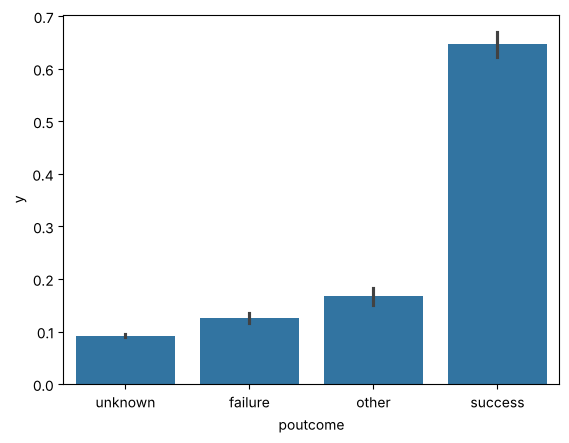

In [12]:
sns.barplot(x='poutcome', y='y', data=df.fillna({'poutcome': 'unknown'}))

Trang Kim Đạt 6451071018

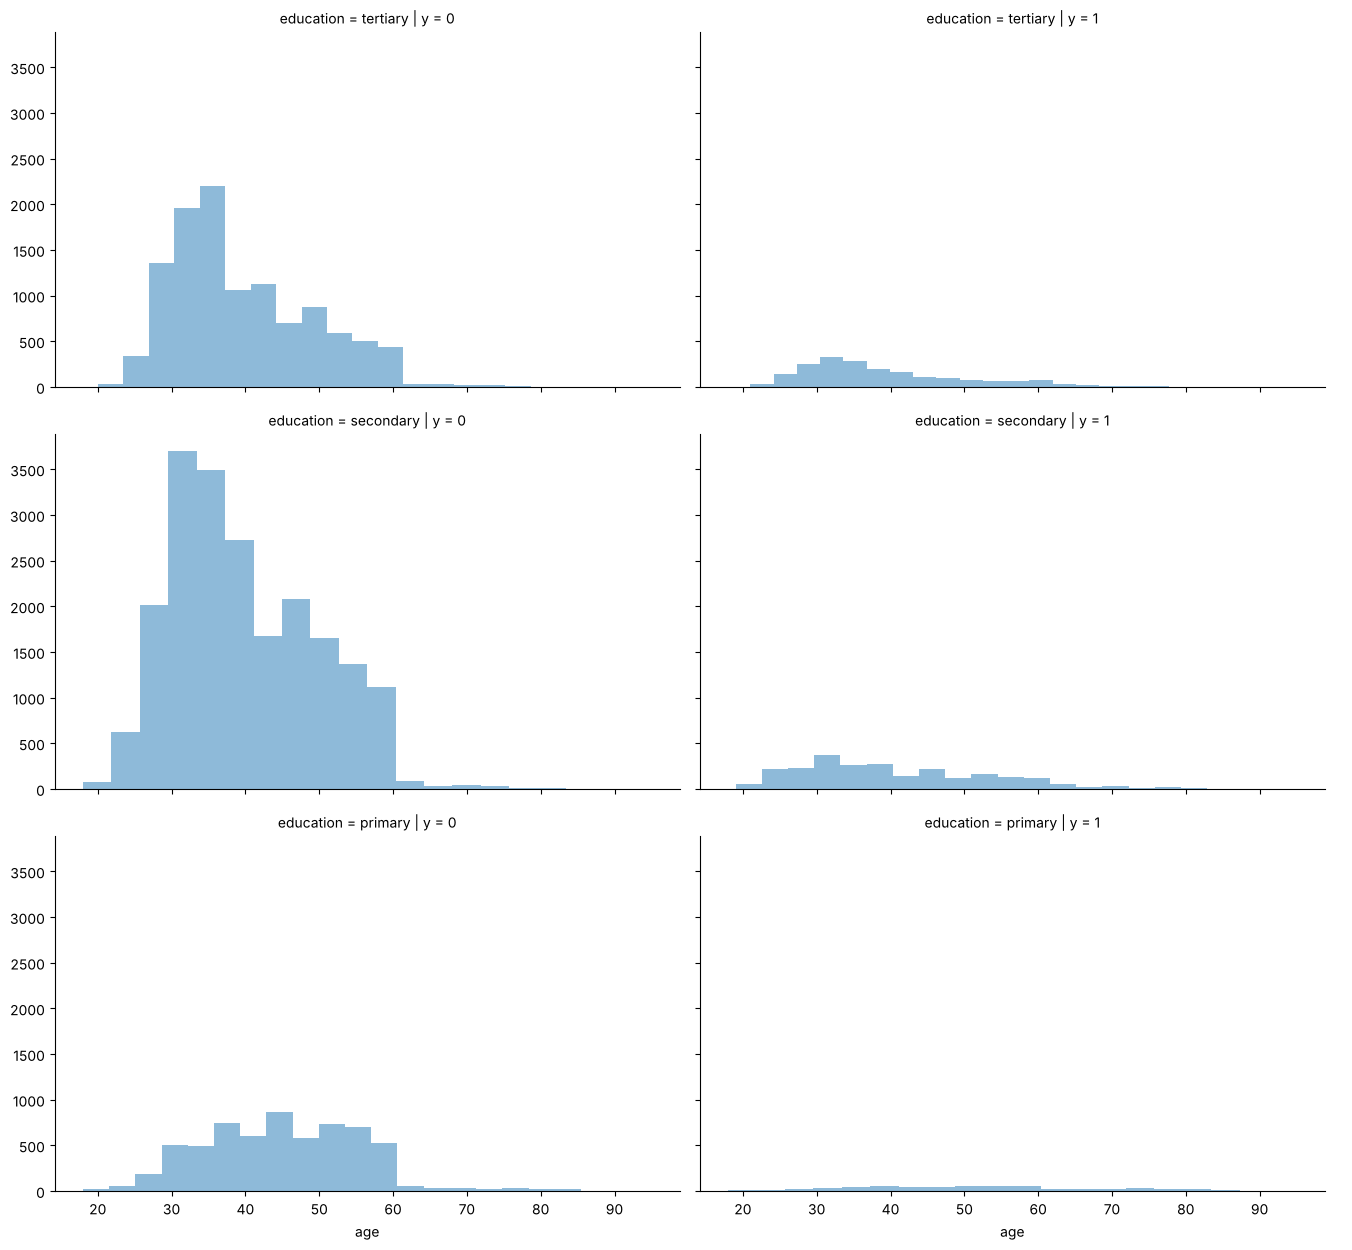

In [13]:
grid = sns.FacetGrid(df.dropna(subset=['education']), col='y', row='education', height=4.2, aspect=1.6)
grid.map(plt.hist, 'age', alpha=.5, bins=20)
grid.add_legend();

Trang Kim Đạt 6451071018

Nhận xét:
- Khách hàng **không** vay mua nhà (housing = no) có tỷ lệ đăng ký cao hơn rõ rệt ở cả hai hình thức liên lạc (cellular: khoảng 20% so với 10%; telephone: khoảng 18% so với 7%).
- Học vấn càng cao thì tỷ lệ đăng ký càng cao: primary khoảng 9%, secondary khoảng 11%, tertiary khoảng 15%.
- Khách hàng đã đăng ký thành công ở chiến dịch trước (poutcome = success) có tỷ lệ đăng ký lại rất cao, khoảng 65%.

## 5. Thống kê số khoản vay của khách hàng (default + housing + loan) và số lần liên lạc

In [14]:
for dataset in [df]:
    dataset['loans'] = (dataset[['default', 'housing', 'loan']] == 'yes').sum(axis=1)
    dataset.loc[dataset['loans'] > 0, 'no_loan'] = 0
    dataset.loc[dataset['loans'] == 0, 'no_loan'] = 1
    dataset['no_loan'] = dataset['no_loan'].astype(int)
df['no_loan'].value_counts()

no_loan
0    28219
1    16992
Name: count, dtype: int64

Trang Kim Đạt 6451071018

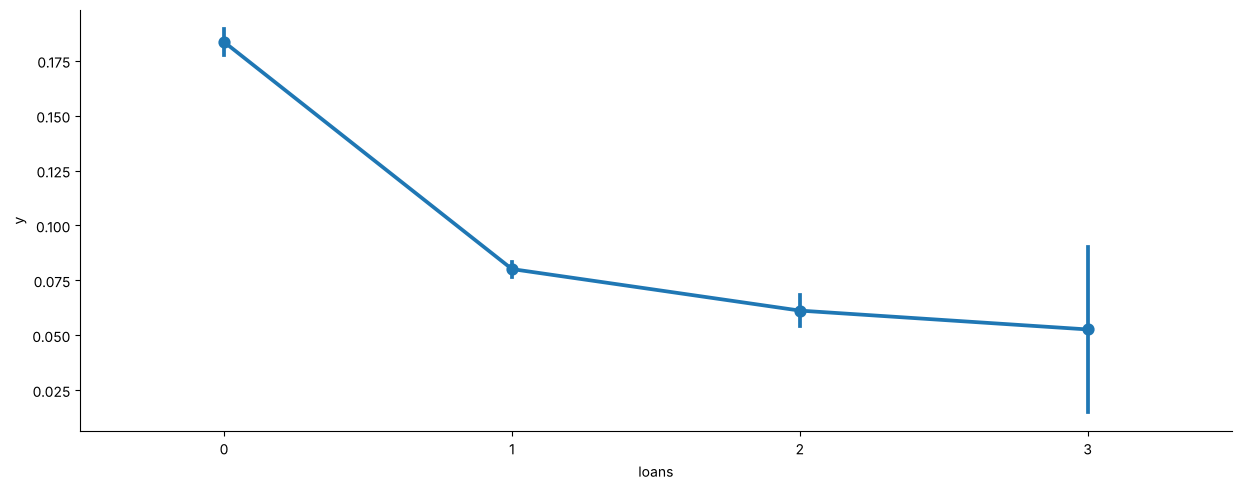

In [15]:
axes = sns.catplot(x='loans', y='y', data=df, aspect=2.5, kind='point')

Trang Kim Đạt 6451071018

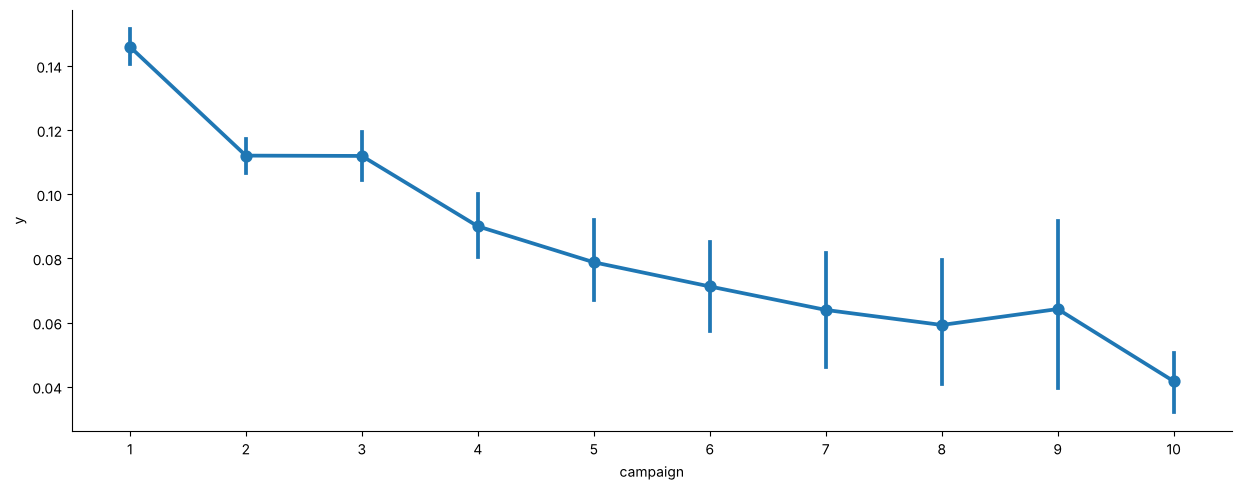

In [16]:
# Số lần liên lạc trong chiến dịch (campaign), gộp các giá trị > 10 vào nhóm 10
axes = sns.catplot(x=df['campaign'].clip(upper=10), y='y', data=df, aspect=2.5, kind='point')

Trang Kim Đạt 6451071018

Nhận xét:
- Số khách hàng không có khoản vay nào là 16,992 người, có ít nhất một khoản vay là 28,219 người.
- Khách hàng không có khoản vay đăng ký nhiều nhất (khoảng 18%); càng nhiều khoản vay thì tỷ lệ càng giảm (1 khoản: khoảng 8%, 2–3 khoản: khoảng 5–6%).
- Liên lạc càng nhiều lần trong chiến dịch thì tỷ lệ đăng ký càng giảm: lần đầu khoảng 15%, từ 10 lần trở lên chỉ khoảng 4%.

## 6. Tiền xử lý dữ liệu
- `poutcome` thiếu hơn 80% → xóa.
- `contact` thiếu gần 29% và chỉ cho biết kênh liên lạc → xóa.
- `day` (ngày trong tháng) không mang nhiều ý nghĩa → xóa.
- `pdays = -1` nghĩa là chưa từng được liên lạc, tách thành thuộc tính `contacted_before` rồi xóa `pdays`.

In [17]:
for dataset in [df]:
    dataset['contacted_before'] = (dataset['pdays'] != -1).astype(int)

df = df.drop(['poutcome'], axis=1)
df = df.drop(['contact'], axis=1)
df = df.drop(['day'], axis=1)
df = df.drop(['pdays'], axis=1)

Điền giá trị thiếu cho `job` và `education` bằng giá trị xuất hiện nhiều nhất (mode).

In [18]:
df['job'].describe()

count           44923
unique             11
top       blue-collar
freq             9732
Name: job, dtype: object

Trang Kim Đạt 6451071018

In [19]:
df['education'].describe()

count         43354
unique            3
top       secondary
freq          23202
Name: education, dtype: object

Trang Kim Đạt 6451071018

In [20]:
for dataset in [df]:
    dataset['job'] = dataset['job'].fillna(dataset['job'].mode()[0])
    dataset['education'] = dataset['education'].fillna(dataset['education'].mode()[0])
df.isnull().sum()

age                 0
job                 0
marital             0
education           0
default             0
balance             0
housing             0
loan                0
month               0
duration            0
campaign            0
previous            0
y                   0
loans               0
no_loan             0
contacted_before    0
dtype: int64

Trang Kim Đạt 6451071018

## 7. Biến đổi các thuộc tính

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   age               45211 non-null  int64
 1   job               45211 non-null  str  
 2   marital           45211 non-null  str  
 3   education         45211 non-null  str  
 4   default           45211 non-null  str  
 5   balance           45211 non-null  int64
 6   housing           45211 non-null  str  
 7   loan              45211 non-null  str  
 8   month             45211 non-null  str  
 9   duration          45211 non-null  int64
 10  campaign          45211 non-null  int64
 11  previous          45211 non-null  int64
 12  y                 45211 non-null  int64
 13  loans             45211 non-null  int64
 14  no_loan           45211 non-null  int64
 15  contacted_before  45211 non-null  int64
dtypes: int64(9), str(7)
memory usage: 5.5 MB


Trang Kim Đạt 6451071018

Các thuộc tính nhị phân yes/no → 1/0

In [22]:
binary = {"no": 0, "yes": 1}

for dataset in [df]:
    for col in ['default', 'housing', 'loan']:
        dataset[col] = dataset[col].map(binary)

Học vấn (education) có thứ tự (ordinal) → mã hóa theo thứ bậc

In [23]:
edu = {"primary": 0, "secondary": 1, "tertiary": 2}

for dataset in [df]:
    dataset['education'] = dataset['education'].map(edu)

Tháng (month) → số thứ tự tháng

In [24]:
months = {"jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
          "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12}

for dataset in [df]:
    dataset['month'] = dataset['month'].map(months)

Nghề nghiệp (job) và hôn nhân (marital) là nominal, không có thứ bậc → dùng One-hot Encoding

In [25]:
df = pd.get_dummies(df, columns=['job', 'marital'], dtype=int)
df.head()

,age,education,default,balance,housing,loan,month,duration,campaign,previous,...,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,marital_divorced,marital_married,marital_single
0,58,2,0,2143,1,0,5,261,1,0,...,1,0,0,0,0,0,0,0,1,0
1,44,1,0,29,1,0,5,151,1,0,...,0,0,0,0,0,1,0,0,0,1
2,33,1,0,2,1,1,5,76,1,0,...,0,0,0,0,0,0,0,0,1,0
3,47,1,0,1506,1,0,5,92,1,0,...,0,0,0,0,0,0,0,0,1,0
4,33,1,0,1,0,0,5,198,1,0,...,0,0,0,0,0,0,0,0,0,1


Trang Kim Đạt 6451071018

Chia tuổi (age) thành 8 nhóm có số lượng tương đối đều nhau:
- Nhóm 0: ≤ 30 · Nhóm 1: 31–33 · Nhóm 2: 34–36 · Nhóm 3: 37–39
- Nhóm 4: 40–43 · Nhóm 5: 44–48 · Nhóm 6: 49–55 · Nhóm 7: > 55

In [26]:
for dataset in [df]:
    dataset['age'] = dataset['age'].astype(int)
    dataset.loc[ dataset['age'] <= 30, 'age'] = 0
    dataset.loc[(dataset['age'] > 30) & (dataset['age'] <= 33), 'age'] = 1
    dataset.loc[(dataset['age'] > 33) & (dataset['age'] <= 36), 'age'] = 2
    dataset.loc[(dataset['age'] > 36) & (dataset['age'] <= 39), 'age'] = 3
    dataset.loc[(dataset['age'] > 39) & (dataset['age'] <= 43), 'age'] = 4
    dataset.loc[(dataset['age'] > 43) & (dataset['age'] <= 48), 'age'] = 5
    dataset.loc[(dataset['age'] > 48) & (dataset['age'] <= 55), 'age'] = 6
    dataset.loc[ dataset['age'] > 55, 'age'] = 7

Lưu ý: các điều kiện chạy tuần tự, nhóm vừa gán (0–7) đều ≤ 30 nên không bị điều kiện sau ghi đè.

In [27]:
df['age'].value_counts().sort_index()

age
0    7030
1    6053
2    5630
3    4649
4    5049
5    5612
6    6288
7    4900
Name: count, dtype: int64

Trang Kim Đạt 6451071018

Chia số dư tài khoản (balance) thành 6 nhóm cân bằng bằng `pd.qcut`:
- Gợi ý ranh giới: ≤ 2, 2–175, 175–448, 448–955, 955–2283, > 2283

In [28]:
for dataset in [df]:
    dataset['balance'] = pd.qcut(dataset['balance'], q=6, labels=False, duplicates='drop')
df['balance'].value_counts().sort_index()

balance
0    7631
1    7444
2    7533
3    7533
4    7535
5    7535
Name: count, dtype: int64

Trang Kim Đạt 6451071018

## 8. Tạo thuộc tính mới

In [5]:
# Tuổi * học vấn (age_edu)
import pandas as pd

for dataset in [df]:
    dataset['education'] = pd.to_numeric(
        dataset['education'], errors='coerce'
    )

    dataset['age_edu'] = dataset['age'] * (dataset['education'] + 1)

In [11]:
# Thời lượng gọi trung bình mỗi lần liên lạc (duration_per_call), làm trơn +1 như fare_per_person
for dataset in [df]:
    dataset['duration_per_call'] = dataset['duration'] / (dataset['campaign'] + 1)
    dataset['duration_per_call'] = dataset['duration_per_call'].astype(int)

df.head(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,age_edu,duration_per_call
0,58,management,married,NaN,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no,NaN,130
1,44,technician,single,NaN,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no,NaN,75
2,33,entrepreneur,married,NaN,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no,NaN,38
3,47,blue-collar,married,NaN,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no,NaN,46
4,33,unknown,single,NaN,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no,NaN,99
5,35,management,married,NaN,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no,NaN,69
6,28,management,single,NaN,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no,NaN,108
7,42,entrepreneur,divorced,NaN,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no,NaN,190
8,58,retired,married,NaN,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no,NaN,25
9,43,technician,single,NaN,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no,NaN,27


Trang Kim Đạt 6451071018

## 9. Chuẩn hóa Min-max cho các thuộc tính số (đưa về [0, 1])

In [31]:
num_cols = ['duration', 'campaign', 'previous', 'duration_per_call']
for col in num_cols:
    df[col] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())
df[num_cols].describe()

,duration,campaign,previous,duration_per_call
count,45211.000000,45211.000000,45211.000000,45211.000000
mean,0.052494,0.028449,0.002110,0.037233
std,0.052364,0.049968,0.008376,0.041288
min,0.000000,0.000000,0.000000,0.000000
25%,0.020943,0.000000,0.000000,0.012200
50%,0.036600,0.016129,0.000000,0.024807
75%,0.064864,0.032258,0.000000,0.047174
max,1.000000,1.000000,1.000000,1.000000


Trang Kim Đạt 6451071018

In [32]:
# Xem lại dữ liệu sau khi tiền xử lý
df.head(10)

,age,education,default,balance,housing,loan,month,duration,campaign,previous,...,job_self-employed,job_services,job_student,job_technician,job_unemployed,marital_divorced,marital_married,marital_single,age_edu,duration_per_call
0,7,2,0,4,1,0,5,0.053070,0.0,0.0,...,0,0,0,0,0,0,1,0,21,0.052867
1,5,1,0,1,1,0,5,0.030704,0.0,0.0,...,0,0,0,1,0,0,0,1,10,0.030500
2,1,1,0,0,1,1,5,0.015453,0.0,0.0,...,0,0,0,0,0,0,1,0,2,0.015453
3,5,1,0,4,1,0,5,0.018707,0.0,0.0,...,0,0,0,0,0,0,1,0,10,0.018707
4,1,1,0,0,0,0,5,0.040260,0.0,0.0,...,0,0,0,0,0,0,0,1,2,0.040260
5,2,2,0,2,1,0,5,0.028264,0.0,0.0,...,0,0,0,0,0,0,1,0,6,0.028060
6,0,2,0,2,1,1,5,0.044124,0.0,0.0,...,0,0,0,0,0,0,0,1,0,0.043920
7,4,2,1,0,1,0,5,0.077267,0.0,0.0,...,0,0,0,0,0,1,0,0,12,0.077267
8,7,0,0,1,1,0,5,0.010167,0.0,0.0,...,0,0,0,0,0,0,1,0,7,0.010167
9,4,1,0,3,1,0,5,0.011183,0.0,0.0,...,0,0,0,1,0,0,0,1,8,0.010980


Trang Kim Đạt 6451071018